# Policy Evaluation Comparison

This notebook loads multiple evaluation report JSON files, extracts the main statistics for each policy, and builds:

- a summary comparison table
- four bar charts for quick visual comparison

The main metrics used are:

- success rate
- average simulation time
- average coverage ratio
- average detected objects percentage

The detected objects percentage is computed dynamically from the JSON contents.

In [1]:
from pathlib import Path
import json
import math

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Optional: make pandas tables a bit easier to read
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 120)

## Input paths

Edit the list below to point to the evaluation report JSON files you want to compare.

You can add or remove paths as needed.

In [2]:
# =========================================
# EDIT THIS CELL ONLY WHEN CHANGING REPORTS
# =========================================

REPORT_PATHS = [
    "../logs/eval_aif_weighted_eps004_vel50/eval_report/eval_report.json",
    "../logs/eval_pseudo_random_rand_spawn/eval_report/eval_report.json",
    "../logs/eval_wall_following_rand_spawn/eval_report/eval_report.json",
    "../logs/eval_spiral_rand_spawn/eval_report/eval_report.json",
    "../logs/eval_rotate_and_measure_rand_spawn/eval_report/eval_report.json",
]

POLICY_ORDER = [
    "aif_saccade",
    "pseudo_random",
    "wall_following",
    "spiral",
    "rotate_and_measure",
]

POLICY_LABELS = {
    "aif_saccade": "AIF Saccade",
    "pseudo_random": "Pseudo Random",
    "wall_following": "Wall Following",
    "spiral": "Spiral",
    "rotate_and_measure": "Rotate and Measure",
}

## Helper functions

These functions load each report, normalize policy names, and compute a robust summary row for each experiment.

In [3]:
def normalize_policy_name(name: str) -> str:
    """
    Normalize policy names to a consistent snake_case format.
    """
    if name is None:
        return "unknown"

    cleaned = (
        str(name)
        .strip()
        .lower()
        .replace("-", "_")
        .replace(" ", "_")
    )

    aliases = {
        "aifsaccade": "aif_saccade",
        "aif_saccade": "aif_saccade",
        "pseudo_random": "pseudo_random",
        "pseudorandom": "pseudo_random",
        "wall_following": "wall_following",
        "wallfollowing": "wall_following",
        "spiral": "spiral",
        "rotate_and_measure": "rotate_and_measure",
        "rotateandmeasure": "rotate_and_measure",
    }

    return aliases.get(cleaned, cleaned)


def prettify_policy_name(policy: str) -> str:
    return POLICY_LABELS.get(policy, policy.replace("_", " ").title())


def load_json(path: str) -> dict:
    path_obj = Path(path)
    if not path_obj.exists():
        raise FileNotFoundError(f"File not found: {path}")
    with open(path_obj, "r", encoding="utf-8") as f:
        return json.load(f)


def infer_total_objects_from_runs(runs: list) -> float:
    """
    Infer total number of objects from run data without hard-coding.
    Usually this is found_count + remaining_objects.
    Returns the average total across runs for robustness.
    """
    totals = []

    for run in runs:
        found = run.get("found_count")
        remaining = run.get("remaining_objects")

        if found is not None and remaining is not None:
            totals.append(found + remaining)

    if not totals:
        return math.nan

    return sum(totals) / len(totals)


def build_summary_row(report_path: str) -> dict:
    data = load_json(report_path)

    summary = data.get("summary", {})
    runs = data.get("runs", [])

    # Prefer the top-level policy field, then fall back if needed
    top_policy = data.get("policy")
    run_policy = runs[0].get("policy") if runs else None
    policy = normalize_policy_name(top_policy or run_policy)

    num_runs = data.get("num_runs", len(runs))

    success_rate = summary.get("success_rate", math.nan)
    avg_sim_time = summary.get("average_simulation_time_s", math.nan)
    avg_coverage = summary.get("average_coverage_ratio", math.nan)
    avg_found = summary.get("average_found_count", math.nan)

    total_objects = infer_total_objects_from_runs(runs)

    if pd.notna(avg_found) and pd.notna(total_objects) and total_objects > 0:
        avg_detected_pct = (avg_found / total_objects) * 100.0
    else:
        avg_detected_pct = math.nan

    return {
        "policy": policy,
        "policy_label": prettify_policy_name(policy),
        "num_runs": num_runs,
        "success_rate": success_rate,
        "avg_simulation_time_s": avg_sim_time,
        "avg_coverage_ratio": avg_coverage,
        "avg_found_count": avg_found,
        "inferred_total_objects": total_objects,
        "avg_detected_objects_pct": avg_detected_pct,
        "report_path": report_path,
    }

## Load all reports and build the comparison dataframe

In [4]:
rows = [build_summary_row(path) for path in REPORT_PATHS]
summary_df = pd.DataFrame(rows)

summary_df["policy_sort_key"] = summary_df["policy"].apply(
    lambda p: POLICY_ORDER.index(p) if p in POLICY_ORDER else len(POLICY_ORDER)
)
summary_df = (
    summary_df
    .sort_values(["policy_sort_key", "policy_label"])
    .drop(columns=["policy_sort_key"])
    .reset_index(drop=True)
)

display(summary_df)

,policy,policy_label,num_runs,success_rate,avg_simulation_time_s,avg_coverage_ratio,avg_found_count,inferred_total_objects,avg_detected_objects_pct,report_path
0,aif_saccade,AIF Saccade,10,1.0,90.4032,0.334266,6.0,6.0,100.000000,../logs/eval_aif_weighted_eps004_vel50/eval_report/eval_report.json
1,pseudo_random,Pseudo Random,10,0.2,175.2768,0.428671,4.8,6.0,80.000000,../logs/eval_pseudo_random_rand_spawn/eval_report/eval_report.json
2,wall_following,Wall Following,10,0.2,159.0816,0.281818,4.4,6.0,73.333333,../logs/eval_wall_following_rand_spawn/eval_report/eval_report.json
3,spiral,Spiral,10,0.9,111.3280,0.476923,5.8,6.0,96.666667,../logs/eval_spiral_rand_spawn/eval_report/eval_report.json
4,rotate_and_measure,Rotate and Measure,10,0.0,180.0000,0.184615,2.9,6.0,48.333333,../logs/eval_rotate_and_measure_rand_spawn/eval_report/eval_report.json


## Main comparison table

This table shows the key metrics for each policy.

Percent-based quantities are shown on a 0–100 scale for readability.

In [5]:
comparison_table = summary_df.copy()

comparison_table["success_rate_pct"] = comparison_table["success_rate"] * 100.0
comparison_table["avg_coverage_pct"] = comparison_table["avg_coverage_ratio"] * 100.0

comparison_table = comparison_table[
    [
        "policy_label",
        "num_runs",
        "success_rate_pct",
        "avg_simulation_time_s",
        "avg_coverage_pct",
        "avg_detected_objects_pct",
    ]
].rename(
    columns={
        "policy_label": "Policy",
        "num_runs": "Runs",
        "success_rate_pct": "Success Rate (%)",
        "avg_simulation_time_s": "Avg Simulation Time (s)",
        "avg_coverage_pct": "Avg Coverage (%)",
        "avg_detected_objects_pct": "Avg Detected Objects (%)",
    }
)

comparison_table = comparison_table.round(2)
display(comparison_table)

,Policy,Runs,Success Rate (%),Avg Simulation Time (s),Avg Coverage (%),Avg Detected Objects (%)
0,AIF Saccade,10,100.0,90.40,33.43,100.00
1,Pseudo Random,10,20.0,175.28,42.87,80.00
2,Wall Following,10,20.0,159.08,28.18,73.33
3,Spiral,10,90.0,111.33,47.69,96.67
4,Rotate and Measure,10,0.0,180.00,18.46,48.33


## Styled comparison table

This version adds simple highlighting to make comparisons quicker.

## Bar charts

The following charts compare the four main metrics across policies:

1. success rate
2. average simulation time
3. average coverage
4. average detected objects percentage

In [6]:
plot_df = summary_df.copy()

# plot_df["success_rate_pct"] = plot_df["success_rate"] * 100.0
# plot_df["avg_coverage_pct"] = plot_df["avg_coverage_ratio"] * 100.0

# x_labels = plot_df["policy_label"].tolist()

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def plot_metric_bar(
    df,
    label_col,
    value_col,
    title,
    ylabel,
    higher_is_better=True,
    as_percentage=False,
    figsize=(11, 6),
):
    values = df[value_col].astype(float).to_numpy()
    labels = df[label_col].tolist()

    if as_percentage:
        values = values * 100.0

    if higher_is_better:
        best_idx = int(np.nanargmax(values))
    else:
        best_idx = int(np.nanargmin(values))

    best_value = values[best_idx]
    best_label = labels[best_idx]

    default_color = "#8fb9d4"
    best_color = "#d95f02"
    colors = [default_color] * len(values)
    colors[best_idx] = best_color

    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.bar(labels, values, color=colors, edgecolor="black", linewidth=0.8)

    ax.set_title(title, fontsize=16, pad=14)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle="--", alpha=0.35)

    # best-value reference line
    ax.axhline(
        y=best_value,
        linestyle="--",
        linewidth=1.8,
        color=best_color,
        alpha=0.9,
        label="Best",
    )

    # force best value onto y ticks
    current_ticks = list(ax.get_yticks())
    if not any(np.isclose(t, best_value) for t in current_ticks):
        current_ticks.append(best_value)
        current_ticks = sorted(current_ticks)
        ax.set_yticks(current_ticks)

    # labels above bars
    y_min, y_max = ax.get_ylim()
    y_range = y_max - y_min if y_max > y_min else 1.0
    offset = 0.015 * y_range

    for i, (bar, v) in enumerate(zip(bars, values)):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + offset,
            f"{v:.2f}",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold" if i == best_idx else "normal",
            color=best_color if i == best_idx else "black",
        )

    # single annotation for best bar
    ax.annotate(
        f"Best: {best_label}",
        xy=(bars[best_idx].get_x() + bars[best_idx].get_width() / 2, best_value),
        xytext=(0, 20),
        textcoords="offset points",
        ha="center",
        color=best_color,
        fontsize=12,
        fontweight="bold",
    )

    plt.xticks(rotation=20, ha="right", fontsize=11)

    # put legend outside plot
    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.01, 1.0),
        frameon=False,
        borderaxespad=0.0,
    )

    plt.tight_layout()
    plt.show()

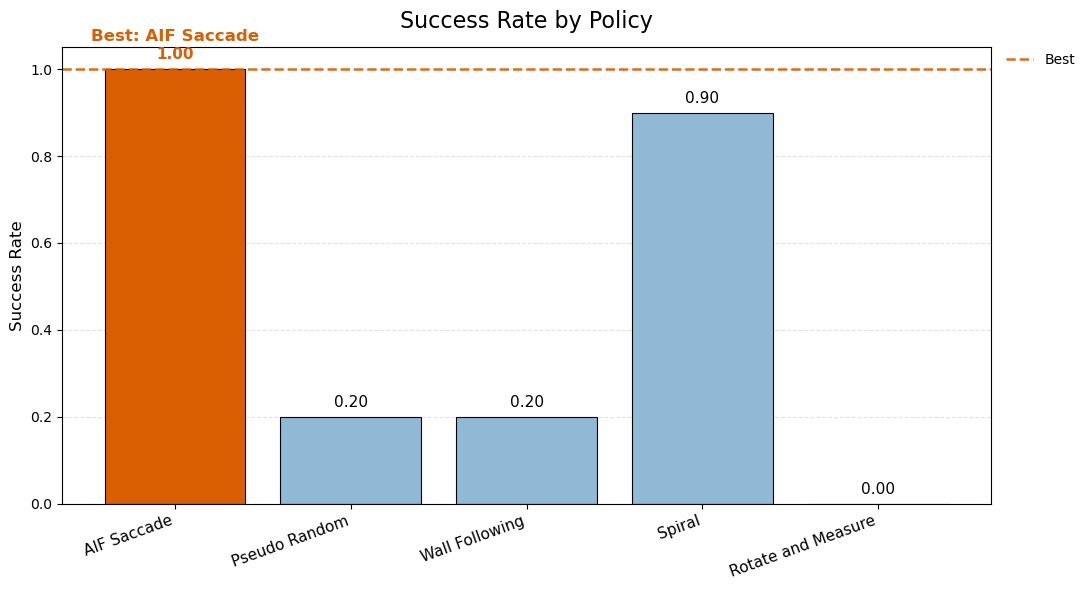

In [8]:
plot_metric_bar(
    df=plot_df,
    label_col="policy_label",
    value_col="success_rate",
    title="Success Rate by Policy",
    ylabel="Success Rate",
    higher_is_better=True,
)

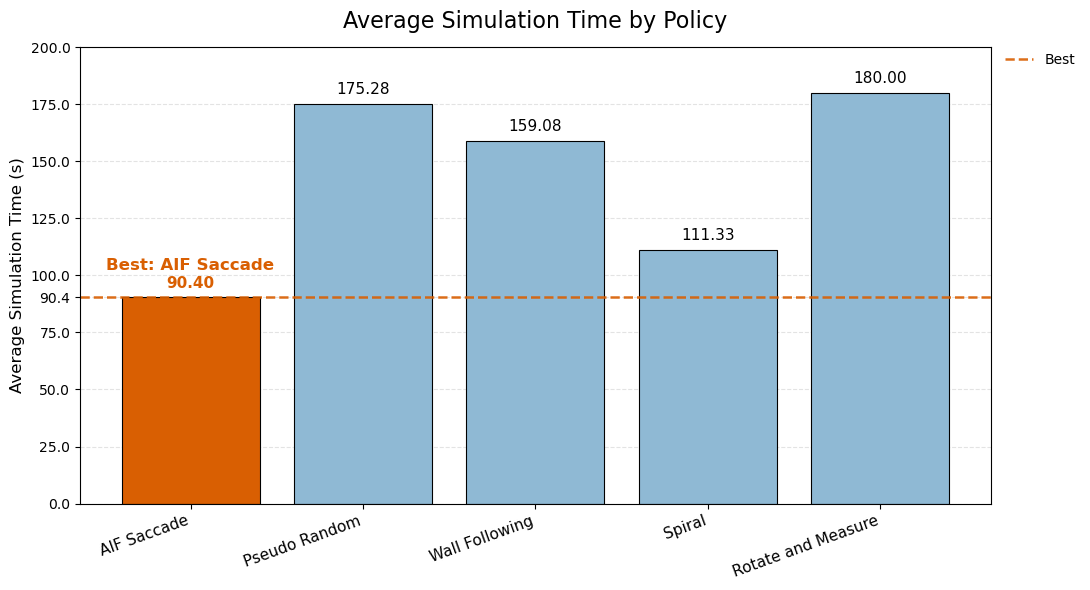

In [9]:
plot_metric_bar(
    df=plot_df,
    label_col="policy_label",
    value_col="avg_simulation_time_s",
    title="Average Simulation Time by Policy",
    ylabel="Average Simulation Time (s)",
    higher_is_better=False,
)

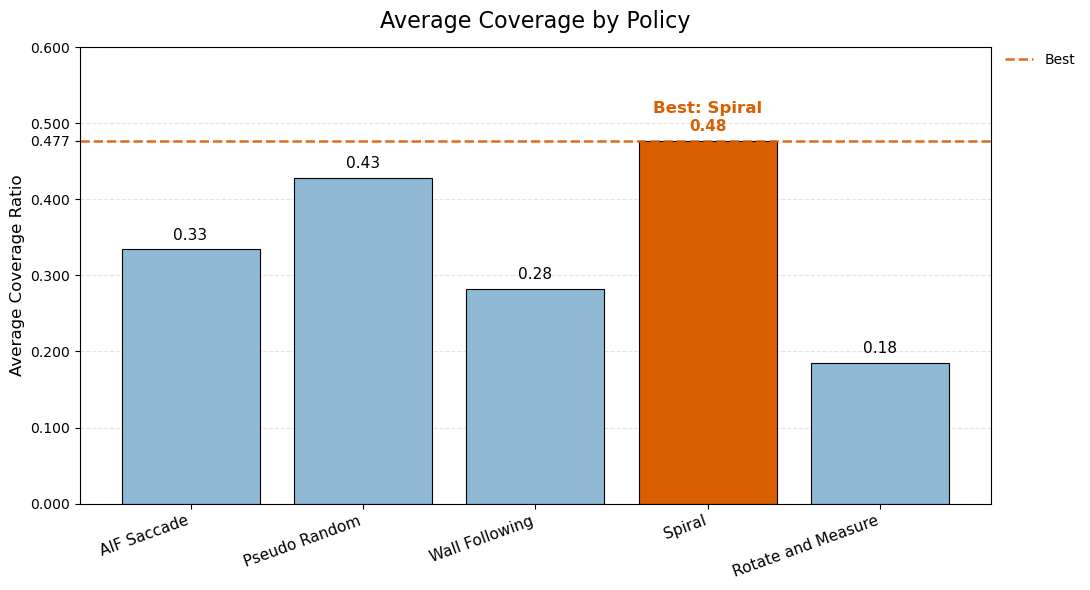

In [ ]:
plot_metric_bar(
    df=plot_df,
    label_col="policy_label",
    value_col="avg_coverage_ratio",
    title="Average Coverage by Policy",
    ylabel="Average Coverage Ratio",
    higher_is_better=False,
)

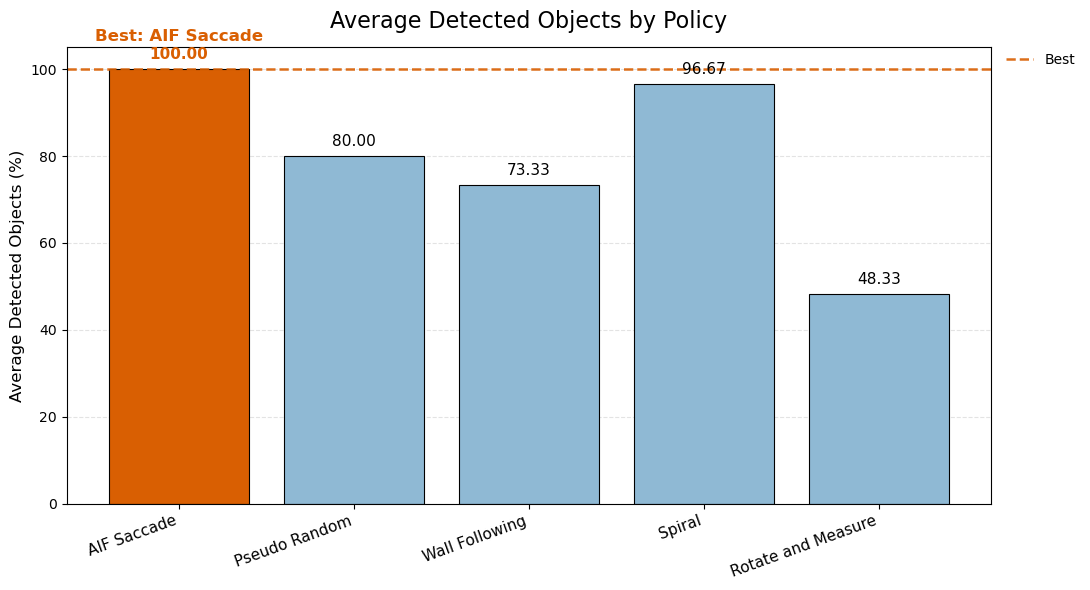

In [11]:
plot_metric_bar(
    df=plot_df,
    label_col="policy_label",
    value_col="avg_detected_objects_pct",
    title="Average Detected Objects by Policy",
    ylabel="Average Detected Objects (%)",
    higher_is_better=True,
)

## Compact ranking view

This optional table sorts policies by the metrics that are usually most relevant for evaluation.


In [12]:
ranking_df = comparison_table.sort_values(
    by=["Success Rate (%)", "Avg Detected Objects (%)", "Avg Coverage (%)"],
    ascending=[False, False, False]
).reset_index(drop=True)

display(ranking_df)

,Policy,Runs,Success Rate (%),Avg Simulation Time (s),Avg Coverage (%),Avg Detected Objects (%)
0,AIF Saccade,10,100.0,90.40,33.43,100.00
1,Spiral,10,90.0,111.33,47.69,96.67
2,Pseudo Random,10,20.0,175.28,42.87,80.00
3,Wall Following,10,20.0,159.08,28.18,73.33
4,Rotate and Measure,10,0.0,180.00,18.46,48.33


## Export results

This optional cell saves the summary table to CSV for later use in reports or papers.

In [13]:
output_csv = "policy_comparison_summary.csv"
comparison_table.to_csv(output_csv, index=False)
print(f"Saved summary table to: {output_csv}")

Saved summary table to: policy_comparison_summary.csv
